# Does a small network learn a carry signal?

I trained a small network to add two 2-bit numbers. My question is whether a hidden neuron responds to a carry from the lowest bit, and whether removing it changes the answer.

Based on the course [starter notebook](https://github.com/AIPI-590-XAI/Duke-AI-XAI/blob/main/assignments/mechanistic_interp_starter.ipynb). I changed the task from counting ones to binary addition.

In [1]:
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.set_num_threads(1)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

## 1. Train the model

The inputs are `[a_high, a_low, b_high, b_low]`. The outputs are the three bits of the sum, from highest to lowest. There are only 16 input pairs, so I train on all of them. The accuracy below measures this full truth table, not generalization to unseen examples.

My starting hypothesis is that a neuron may activate more when both low bits are 1. The carry labels are used only for analysis, not as training targets.

I use seed 0 for the main example because it learned all 16 sums. My first run, seed 42, learned only 14; I include it in the seed comparison below.

In [2]:
pairs = [(a, b) for a in range(4) for b in range(4)]
X = torch.tensor([[a >> 1, a & 1, b >> 1, b & 1] for a, b in pairs], dtype=torch.float32)
y = torch.tensor([[(a+b) >> 2, ((a+b) >> 1) & 1, (a+b) & 1]
                  for a, b in pairs], dtype=torch.float32)
carry = np.array([(a & 1) == 1 and (b & 1) == 1 for a, b in pairs])
labels = [f"{a:02b}+{b:02b}" for a, b in pairs]
sums = np.array([a+b for a, b in pairs])

class AdditionMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(4, 16)
        self.fc2 = nn.Linear(16, 3)

    def forward(self, x):
        h = F.relu(self.fc1(x))
        return self.fc2(h), h

def train_model(seed):
    torch.manual_seed(seed)
    model = AdditionMLP()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.03)
    for step in range(3000):
        logits, _ = model(X)
        loss = F.binary_cross_entropy_with_logits(logits, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return model.eval()

model = train_model(0)
with torch.no_grad():
    logits, hidden = model(X)
correct = ((logits > 0) == y.bool()).all(dim=1)
print(f"Exact sums correct: {correct.sum().item()}/16")
print("Input      True  Predicted")
for label, target, pred in zip(labels, y.int(), (logits > 0).int()):
    print(f"{label}    {''.join(map(str, target.tolist()))}   {''.join(map(str, pred.tolist()))}")

Exact sums correct: 16/16
Input      True  Predicted
00+00    000   000
00+01    001   001
00+10    010   010
00+11    011   011
01+00    001   001
01+01    010   010
01+10    011   011
01+11    100   100
10+00    010   010
10+01    011   011
10+10    100   100
10+11    101   101
11+00    011   011
11+01    100   100
11+10    101   101
11+11    110   110


## 2. Look inside

I compare every hidden neuron before choosing one. The selection score is the mean activation difference (carry minus no carry), divided by the neuron's standard deviation across all inputs. This avoids picking a neuron just because its activations have a larger scale. Neuron numbers start at 0.

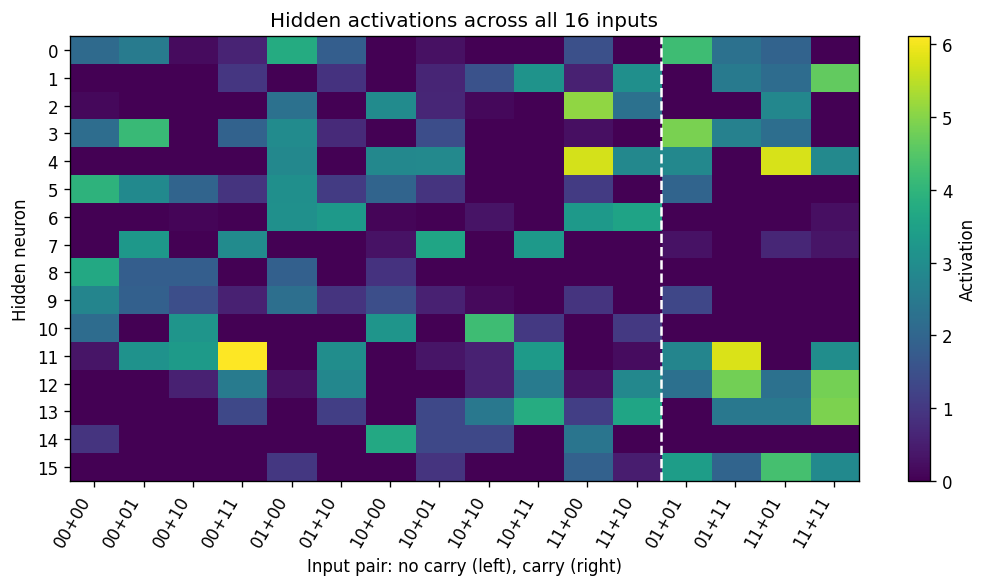

Selected neuron: 15; score: 2.03


In [3]:
def select_neuron(h):
    activations = h.numpy()
    difference = activations[carry].mean(axis=0) - activations[~carry].mean(axis=0)
    scores = difference / np.maximum(activations.std(axis=0), 1e-8)
    return int(scores.argmax()), scores

neuron, scores = select_neuron(hidden)
activations = hidden.numpy()
order = np.argsort(carry, kind="stable")
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(activations[order].T, aspect="auto", cmap="viridis")
ax.set_xticks(range(16), [labels[i] for i in order], rotation=60, ha="right")
ax.set_yticks(range(16))
ax.axvline(11.5, color="white", linestyle="--")
ax.set(xlabel="Input pair: no carry (left), carry (right)", ylabel="Hidden neuron",
       title="Hidden activations across all 16 inputs")
fig.colorbar(im, ax=ax, label="Activation")
plt.tight_layout()
plt.show()
print(f"Selected neuron: {neuron}; score: {scores[neuron]:.2f}")

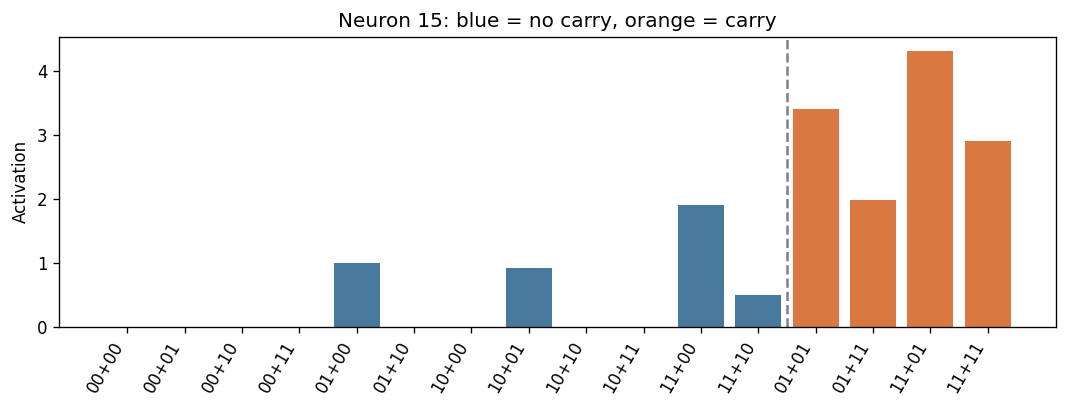

Mean activation, carry: 3.144
Mean activation, no carry: 0.357
Carry range: 1.979 to 4.308
No-carry range: 0.000 to 1.902

Same answer, different carry conditions:
Sum 2: carry mean = 3.396, no-carry mean = 0.000
Sum 4: carry mean = 3.144, no-carry mean = 0.000


In [4]:
values = activations[:, neuron]
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(range(16), values[order], color=["#d97941" if carry[i] else "#46799b" for i in order])
ax.set_xticks(range(16), [labels[i] for i in order], rotation=60, ha="right")
ax.axvline(11.5, color="gray", linestyle="--")
ax.set(ylabel="Activation", title=f"Neuron {neuron}: blue = no carry, orange = carry")
plt.tight_layout()
plt.show()
print(f"Mean activation, carry: {values[carry].mean():.3f}")
print(f"Mean activation, no carry: {values[~carry].mean():.3f}")
print(f"Carry range: {values[carry].min():.3f} to {values[carry].max():.3f}")
print(f"No-carry range: {values[~carry].min():.3f} to {values[~carry].max():.3f}")

# Compare cases with the same sum, so the output alone cannot explain the difference.
print("\nSame answer, different carry conditions:")
for total in sorted(set(sums[carry]) & set(sums[~carry])):
    yes = values[(sums == total) & carry].mean()
    no = values[(sums == total) & ~carry].mean()
    print(f"Sum {total}: carry mean = {yes:.3f}, no-carry mean = {no:.3f}")

## 3. Remove neurons

Activation differences show an association. To test the neuron's role, I set its activation to zero and keep all other weights and activations unchanged. I repeat this for every neuron as a comparison.

I measure the increase in binary cross-entropy, averaged over the three output bits. A larger increase means worse predictions. The groups contain 4 carry cases and 12 no-carry cases, so I compare group means.

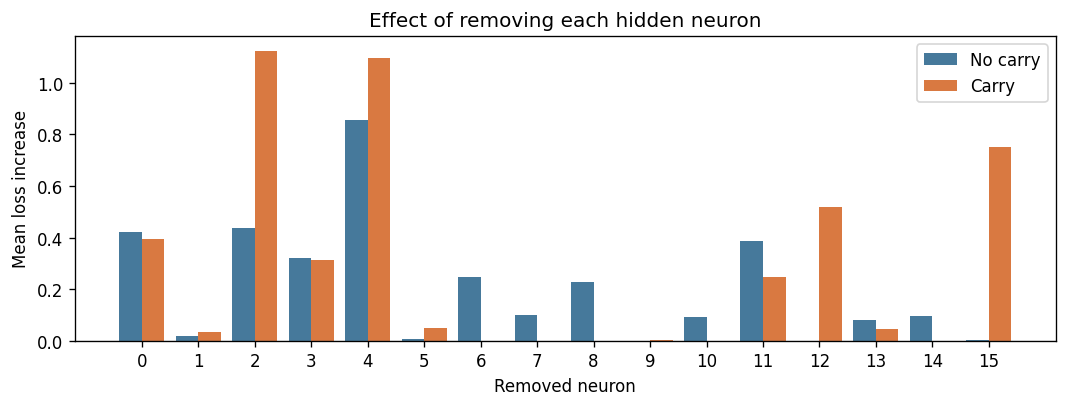

Removing neuron 15:
Carry: 4/4 correct before, 1/4 after; mean loss increase = 0.751
No carry: 12/12 correct before, 12/12 after; mean loss increase = 0.001
Changed answers:
01+01: 010 -> 000
11+01: 100 -> 101
11+11: 110 -> 100


In [5]:
def ablation_results(model):
    with torch.no_grad():
        base, h = model(X)
        base_loss = F.binary_cross_entropy_with_logits(base, y, reduction="none").mean(dim=1)
        changes, predictions = [], []
        for j in range(16):
            modified = h.clone()
            modified[:, j] = 0
            out = model.fc2(modified)
            loss = F.binary_cross_entropy_with_logits(out, y, reduction="none").mean(dim=1)
            changes.append((loss - base_loss).numpy())
            predictions.append((out > 0).numpy())
    return np.array(changes), np.array(predictions)

changes, predictions = ablation_results(model)
carry_effect = changes[:, carry].mean(axis=1)
no_carry_effect = changes[:, ~carry].mean(axis=1)
fig, ax = plt.subplots(figsize=(9, 3.5))
positions = np.arange(16)
ax.bar(positions - 0.2, no_carry_effect, width=0.4, label="No carry", color="#46799b")
ax.bar(positions + 0.2, carry_effect, width=0.4, label="Carry", color="#d97941")
ax.set_xticks(positions)
ax.set(xlabel="Removed neuron", ylabel="Mean loss increase", title="Effect of removing each hidden neuron")
ax.axhline(0, color="gray", linewidth=0.7)
ax.legend()
plt.tight_layout()
plt.show()

ablated_correct = (predictions[neuron] == y.numpy()).all(axis=1)
print(f"Removing neuron {neuron}:")
for name, mask in [("Carry", carry), ("No carry", ~carry)]:
    print(f"{name}: {correct.numpy()[mask].sum()}/{mask.sum()} correct before, "
          f"{ablated_correct[mask].sum()}/{mask.sum()} after; "
          f"mean loss increase = {changes[neuron, mask].mean():.3f}")
print("Changed answers:")
for i in np.where(~ablated_correct & correct.numpy())[0]:
    print(f"{labels[i]}: {''.join(map(str, y[i].int().tolist()))} -> "
          f"{''.join(map(str, predictions[neuron, i].astype(int)))}")

## 4. Check other training seeds

I repeat the same procedure with seeds 1, 2, and 42, choosing each model's neuron by the same activation score. I report every run. The neuron numbers need not match because each model starts from different weights.

In [6]:
print("Seed | Correct sums | Neuron | Activation score | Loss increase: carry / no carry")
seed_results = []
for seed in [1, 2, 42]:
    other = train_model(seed)
    with torch.no_grad():
        out, h = other(X)
    j, s = select_neuron(h)
    delta, _ = ablation_results(other)
    accuracy = ((out > 0) == y.bool()).all(dim=1).sum().item()
    yes, no = delta[j, carry].mean(), delta[j, ~carry].mean()
    seed_results.append((seed, accuracy, j, float(s[j]), float(yes), float(no)))
    print(f"{seed:4d} | {accuracy:2d}/16        | {j:6d} | {s[j]:16.2f} | {yes:.3f} / {no:.3f}")

Seed | Correct sums | Neuron | Activation score | Loss increase: carry / no carry
   1 | 16/16        |      4 |             2.26 | 1.973 / 0.000
   2 | 16/16        |     14 |             2.24 | 0.402 / 0.000
  42 | 14/16        |     13 |             2.31 | 0.632 / -0.000


## What I found

Neuron 15 appears to help the model handle a carry from the lowest bit. Its mean activation was 3.144 for carry inputs and 0.357 for other inputs. The difference remained when I compared inputs with the same sum.

Removing this neuron reduced correct carry answers from 4/4 to 1/4. All 12 no-carry answers stayed correct. The average loss increase was 0.751 for carry cases and 0.001 for no-carry cases. Together, these results support a role in processing carry-related inputs.

It is not a perfect on/off carry detector: it also activates on some no-carry inputs. Removing it does not prove the network uses the same addition steps as a person. Similar selective effects appeared with other seeds, but seed 42 only learned 14/16 sums. This is a small, exploratory result on the same 16 inputs used for training. With more time, I would test pairs of neurons to see whether they share the work.